In [3]:
pip install yfinance


Note: you may need to restart the kernel to use updated packages.


First five observations:
Ticker            AGG         GLD         SPY
Date                                         
2021-01-04  98.368172  182.330002  341.588715
2021-01-05  98.268173  182.869995  343.941345
2021-01-06  97.784805  179.899994  345.997559
2021-01-07  97.684822  179.479996  351.138245
2021-01-08  97.568184  173.339996  353.139008

Missing observations:
Ticker
AGG    0
GLD    0
SPY    0
dtype: int64

Asset statistics:
        Annualised Mean Return  Annualised Volatility
Ticker                                               
AGG                    -0.0019                 0.0607
GLD                     0.1683                 0.1562
SPY                     0.1520                 0.1711


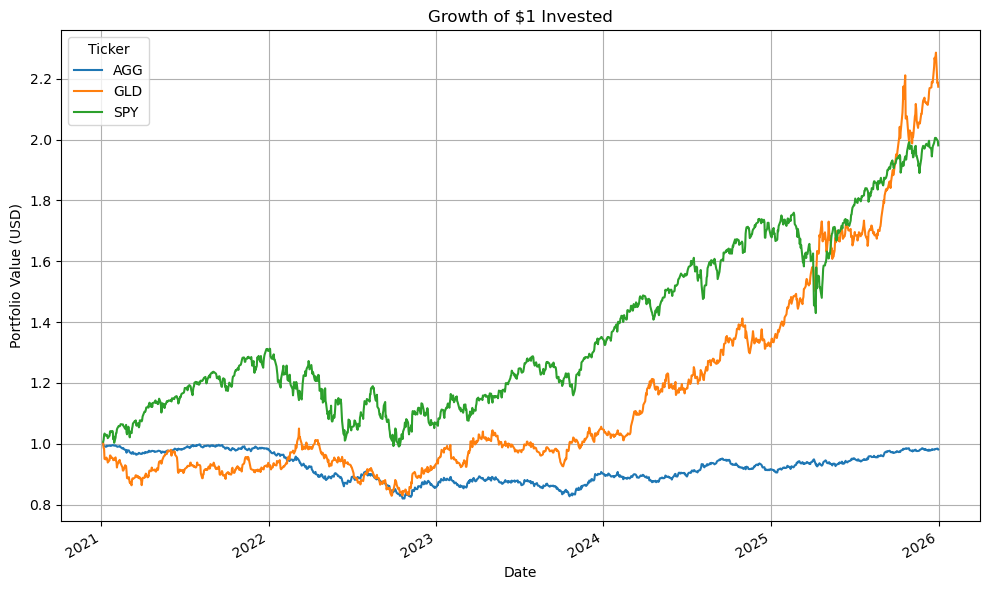

In [4]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# Our initial investment universe
tickers = ["SPY", "AGG", "GLD"]

# Retrieve adjusted daily prices
prices = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"]

# Check the data
print("First five observations:")
print(prices.head())

print("\nMissing observations:")
print(prices.isna().sum())

# Daily simple returns
returns = prices.pct_change(fill_method=None).dropna()

# Cumulative growth of $1
growth = (1 + returns).cumprod()

# Summary statistics
annual_returns = returns.mean() * 252
annual_volatility = returns.std() * (252 ** 0.5)

summary = pd.DataFrame({
    "Annualised Mean Return": annual_returns,
    "Annualised Volatility": annual_volatility
})

print("\nAsset statistics:")
print(summary.round(4))

# Plot historical growth
growth.plot(figsize=(10, 6))
plt.title("Growth of $1 Invested")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (USD)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [5]:
returns = prices.pct_change(fill_method=None).dropna()

print(returns.head())

Ticker           AGG       GLD       SPY
Date                                    
2021-01-05 -0.001017  0.002962  0.006887
2021-01-06 -0.004919 -0.016241  0.005978
2021-01-07 -0.001022 -0.002335  0.014858
2021-01-08 -0.001194 -0.034210  0.005698
2021-01-11 -0.001623 -0.001961 -0.006741


In [6]:
print(returns.describe())

Ticker          AGG          GLD          SPY
count   1254.000000  1254.000000  1254.000000
mean      -0.000008     0.000668     0.000603
std        0.003823     0.009837     0.010779
min       -0.016393    -0.064269    -0.058543
25%       -0.002279    -0.004696    -0.004521
50%        0.000000     0.000613     0.000746
75%        0.002239     0.006173     0.006306
max        0.021470     0.036991     0.105019


In [7]:
returns.std()

Ticker
AGG    0.003823
GLD    0.009837
SPY    0.010779
dtype: float64

In [8]:
# Annualisation assumptions
trading_days = 252
risk_free_rate = 0.04

# Annualised arithmetic mean returns
annual_returns = returns.mean() * trading_days

# Annualised volatility
annual_volatility = returns.std() * (trading_days ** 0.5)

# Sharpe ratios
sharpe_ratios = (
    annual_returns - risk_free_rate
) / annual_volatility

# Results table
summary = pd.DataFrame({
    "Annual Return": annual_returns,
    "Annual Volatility": annual_volatility,
    "Sharpe Ratio": sharpe_ratios
})

print(summary.round(4))

        Annual Return  Annual Volatility  Sharpe Ratio
Ticker                                                
AGG           -0.0019             0.0607       -0.6903
GLD            0.1683             0.1562        0.8214
SPY            0.1520             0.1711        0.6545


In [9]:
import numpy as np

# Portfolio weights, aligned to asset tickers
weights = pd.Series({
    "SPY": 0.50,
    "AGG": 0.30,
    "GLD": 0.20
})

weights = weights.reindex(returns.columns)

# Annualised covariance matrix
cov_matrix = returns.cov() * 252

# Portfolio annualised expected return
portfolio_return = annual_returns @ weights

# Portfolio annualised volatility
portfolio_volatility = np.sqrt(
    weights.to_numpy() @ cov_matrix.to_numpy() @ weights.to_numpy()
)

# Portfolio Sharpe ratio
portfolio_sharpe = (
    portfolio_return - risk_free_rate
) / portfolio_volatility

print(f"Annual return: {portfolio_return:.2%}")
print(f"Annual volatility: {portfolio_volatility:.2%}")
print(f"Sharpe ratio: {portfolio_sharpe:.3f}")

print("\nCorrelation matrix:")
print(returns.corr().round(3))

Annual return: 10.91%
Annual volatility: 10.14%
Sharpe ratio: 0.681

Correlation matrix:
Ticker    AGG    GLD    SPY
Ticker                     
AGG     1.000  0.333  0.195
GLD     0.333  1.000  0.125
SPY     0.195  0.125  1.000


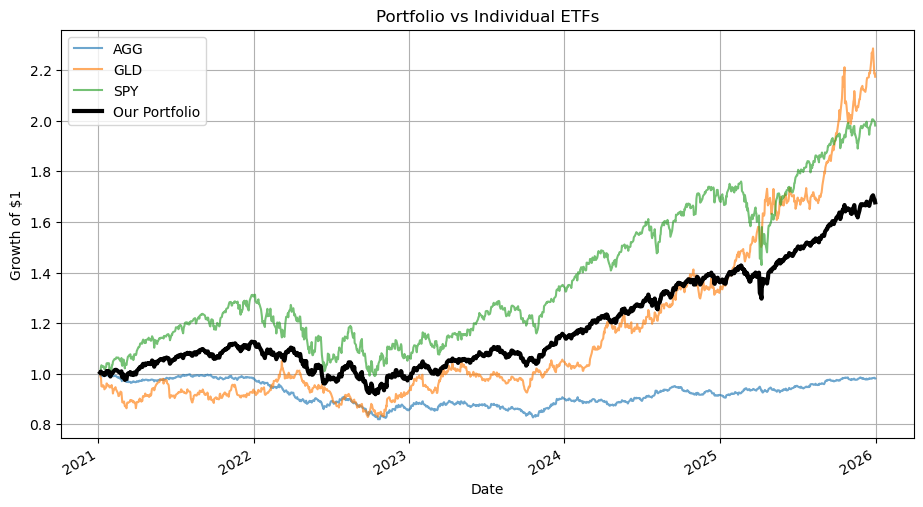

In [10]:
# Daily portfolio returns (constant-weight portfolio)
portfolio_daily_returns = returns @ weights

# Growth of $1
portfolio_growth = (1 + portfolio_daily_returns).cumprod()

# Compare against the individual assets
asset_growth = (1 + returns).cumprod()

ax = asset_growth.plot(figsize=(11, 6), alpha=0.65)

portfolio_growth.plot(
    ax=ax,
    linewidth=3,
    color="black",
    label="Our Portfolio"
)

ax.set_title("Portfolio vs Individual ETFs")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.legend()
ax.grid(True)

plt.show()

Maximum drawdown: -18.44%


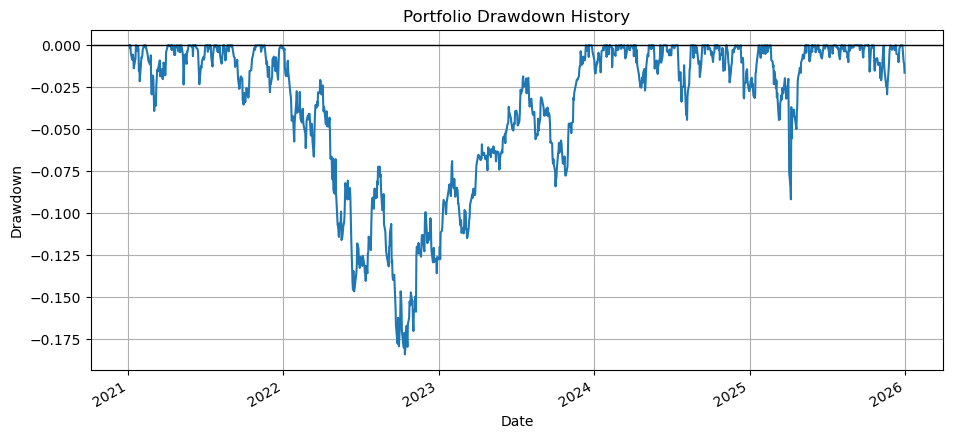

In [11]:
# Track the portfolio's previous highest value
running_peak = portfolio_growth.cummax()

# Calculate drawdowns
drawdowns = portfolio_growth / running_peak - 1

# Find the worst historical drawdown
max_drawdown = drawdowns.min()

print(f"Maximum drawdown: {max_drawdown:.2%}")

# Plot drawdown history
drawdowns.plot(
    figsize=(11, 5),
    title="Portfolio Drawdown History"
)

plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Drawdown")
plt.grid(True)
plt.show()

In [12]:
# Identify worst drawdown date
trough_date = drawdowns.idxmin()

# Identify preceding peak
peak_date = portfolio_growth.loc[:trough_date].idxmax()

print(f"Peak date: {peak_date.date()}")
print(f"Trough date: {trough_date.date()}")
print(f"Maximum drawdown: {max_drawdown:.2%}")

Peak date: 2021-12-27
Trough date: 2022-10-14
Maximum drawdown: -18.44%


In [13]:
# Asset returns during the drawdown period
period_returns = returns.loc[
    (returns.index > peak_date) &
    (returns.index <= trough_date)
]

# Approximate contribution to portfolio return
# using sums of daily weighted returns
contributions = period_returns.mul(weights, axis=1).sum()

print("Approximate asset contributions:")
print((100 * contributions).round(2))

# Individual asset returns over the same period
asset_period_returns = (
    (1 + period_returns).prod() - 1
)

print("\nAsset cumulative returns:")
print((100 * asset_period_returns).round(2))

Approximate asset contributions:
Ticker
AGG    -5.09
GLD    -1.86
SPY   -12.68
dtype: float64

Asset cumulative returns:
Ticker
AGG   -15.82
GLD    -9.68
SPY   -24.20
dtype: float64


In [14]:
# Correlations during the worst drawdown period
crisis_corr = period_returns.corr()

# Compare against full-sample correlations
normal_corr = returns.corr()

print("Full-sample correlations:")
print(normal_corr.round(3))

print("\nDrawdown-period correlations:")
print(crisis_corr.round(3))

print("\nChange in correlations:")
print((crisis_corr - normal_corr).round(3))

Full-sample correlations:
Ticker    AGG    GLD    SPY
Ticker                     
AGG     1.000  0.333  0.195
GLD     0.333  1.000  0.125
SPY     0.195  0.125  1.000

Drawdown-period correlations:
Ticker    AGG    GLD    SPY
Ticker                     
AGG     1.000  0.434  0.259
GLD     0.434  1.000  0.090
SPY     0.259  0.090  1.000

Change in correlations:
Ticker    AGG    GLD    SPY
Ticker                     
AGG     0.000  0.100  0.063
GLD     0.100  0.000 -0.036
SPY     0.063 -0.036  0.000


In [15]:
# Historical simulation VaR and CVaR

confidence = 0.95
alpha = 1 - confidence

# Portfolio daily returns
r = portfolio_daily_returns.dropna()

# Fifth percentile of daily returns
quantile = r.quantile(alpha)

# VaR (positive loss magnitude)
var_95 = -quantile

# CVaR (average loss beyond VaR)
cvar_95 = -r[r <= quantile].mean()

# Express results in dollars
portfolio_value = 100_000

print(f"95% one-day VaR: {var_95:.2%}")
print(f"95% one-day CVaR: {cvar_95:.2%}")

print(f"VaR in USD: ${var_95 * portfolio_value:,.2f}")
print(f"CVaR in USD: ${cvar_95 * portfolio_value:,.2f}")

95% one-day VaR: 0.99%
95% one-day CVaR: 1.43%
VaR in USD: $985.58
CVaR in USD: $1,430.57


In [16]:
import os

print("Current directory:", os.getcwd())
print("Risk module exists:", os.path.exists("src/risk.py"))

Current directory: /Users/admin/portfolio-risk-lab
Risk module exists: True


In [17]:
import importlib
import src.risk

importlib.reload(src.risk)

from src.risk import historical_var, historical_cvar

print(f"Module VaR: {historical_var(portfolio_daily_returns):.2%}")
print(f"Module CVaR: {historical_cvar(portfolio_daily_returns):.2%}")

Module VaR: 0.99%
Module CVaR: 1.43%


In [18]:
from src.risk import historical_var, historical_cvar

for confidence in [0.95, 0.99]:
    var = historical_var(portfolio_daily_returns, confidence)
    cvar = historical_cvar(portfolio_daily_returns, confidence)

    print(f"\nConfidence: {confidence:.0%}")
    print(f"VaR: {var:.2%}")
    print(f"CVaR: {cvar:.2%}")


Confidence: 95%
VaR: 0.99%
CVaR: 1.43%

Confidence: 99%
VaR: 1.74%
CVaR: 2.21%


Monte Carlo 95% VaR: 1.03%
Monte Carlo 95% CVaR: 1.29%


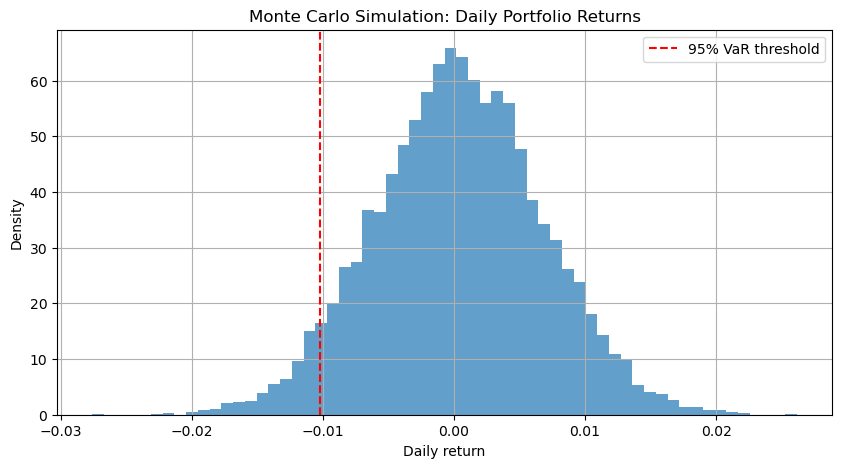

In [19]:

import numpy as np
import matplotlib.pyplot as plt

# Estimate daily return parameters
mu = portfolio_daily_returns.mean()
sigma = portfolio_daily_returns.std()

# Reproducible random-number generator
rng = np.random.default_rng(42)

# Simulate 10,000 possible daily returns
n_simulations = 10_000

simulated_returns = rng.normal(
    loc=mu,
    scale=sigma,
    size=n_simulations
)

# Calculate simulated VaR and CVaR
simulated_var = -np.quantile(simulated_returns, 0.05)

simulated_cvar = -simulated_returns[
    simulated_returns <= -simulated_var
].mean()

print(f"Monte Carlo 95% VaR: {simulated_var:.2%}")
print(f"Monte Carlo 95% CVaR: {simulated_cvar:.2%}")

# Plot the simulated distribution
plt.figure(figsize=(10, 5))

plt.hist(
    simulated_returns,
    bins=60,
    density=True,
    alpha=0.7
)

plt.axvline(
    -simulated_var,
    color="red",
    linestyle="--",
    label="95% VaR threshold"
)

plt.title("Monte Carlo Simulation: Daily Portfolio Returns")
plt.xlabel("Daily return")
plt.ylabel("Density")
plt.legend()
plt.grid(True)
plt.show()


In [20]:
from src.monte_carlo import simulate_normal_returns
from src.risk import historical_var, historical_cvar

simulated = simulate_normal_returns(
    portfolio_daily_returns,
    n_simulations=10_000,
    seed=42
)

print(f"Monte Carlo VaR: {historical_var(simulated):.2%}")
print(f"Monte Carlo CVaR: {historical_cvar(simulated):.2%}")

Monte Carlo VaR: 1.03%
Monte Carlo CVaR: 1.29%


Mean terminal wealth: $111,625.70
Median terminal wealth: $111,003.56
5th percentile: $93,808.57
95th percentile: $131,189.05
Probability of loss: 15.10%


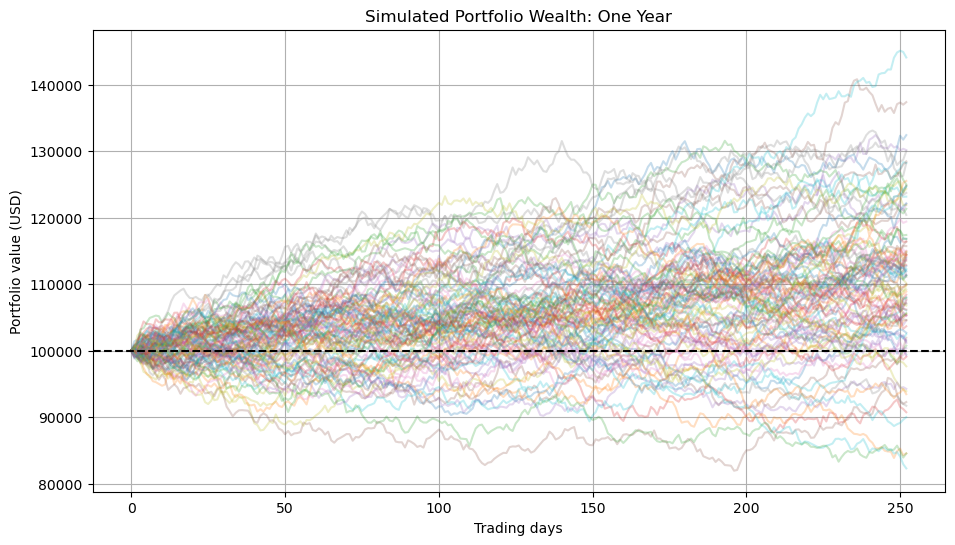

In [21]:

import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
initial_wealth = 100_000
n_days = 252
n_paths = 10_000

# Historical daily return estimates
mu = portfolio_daily_returns.mean()
sigma = portfolio_daily_returns.std()

# Random generator
rng = np.random.default_rng(42)

# Simulate daily returns
simulated_returns = rng.normal(
    loc=mu,
    scale=sigma,
    size=(n_days, n_paths)
)

# Convert daily returns into wealth paths
wealth_paths = initial_wealth * np.vstack([
    np.ones(n_paths),
    np.cumprod(1 + simulated_returns, axis=0)
])

# Terminal wealth
terminal_wealth = wealth_paths[-1]

print(f"Mean terminal wealth: ${terminal_wealth.mean():,.2f}")
print(f"Median terminal wealth: ${np.median(terminal_wealth):,.2f}")
print(f"5th percentile: ${np.percentile(terminal_wealth, 5):,.2f}")
print(f"95th percentile: ${np.percentile(terminal_wealth, 95):,.2f}")

# Probability of losing money
probability_loss = np.mean(
    terminal_wealth < initial_wealth
)

print(f"Probability of loss: {probability_loss:.2%}")

# Plot 100 simulated paths
plt.figure(figsize=(11, 6))

plt.plot(wealth_paths[:, :100], alpha=0.25)
plt.axhline(initial_wealth, color="black", linestyle="--")

plt.title("Simulated Portfolio Wealth: One Year")
plt.xlabel("Trading days")
plt.ylabel("Portfolio value (USD)")
plt.grid(True)
plt.show()


In [22]:
# Running maximum for each simulated path
running_peaks = np.maximum.accumulate(
    wealth_paths, axis=0
)

# Drawdown at each point of each path
simulated_drawdowns = (
    wealth_paths / running_peaks - 1
)

# Worst drawdown for each simulated path
max_drawdowns = simulated_drawdowns.min(axis=0)

print(
    f"Mean maximum drawdown: "
    f"{max_drawdowns.mean():.2%}"
)

print(
    f"Median maximum drawdown: "
    f"{np.median(max_drawdowns):.2%}"
)

print(
    f"5th percentile maximum drawdown: "
    f"{np.percentile(max_drawdowns, 5):.2%}"
)

print(
    f"Probability of drawdown worse than 20%: "
    f"{np.mean(max_drawdowns < -0.20):.2%}"
)

Mean maximum drawdown: -8.13%
Median maximum drawdown: -7.48%
5th percentile maximum drawdown: -14.26%
Probability of drawdown worse than 20%: 0.40%


In [23]:
import importlib
import numpy as np
import src.monte_carlo

importlib.reload(src.monte_carlo)

from src.monte_carlo import simulate_wealth_paths

paths = simulate_wealth_paths(
    portfolio_daily_returns,
    initial_wealth=100_000,
    n_days=252,
    n_paths=10_000,
    seed=42
)

print("Shape:", paths.shape)
print("Mean terminal wealth:", round(paths[-1].mean(), 2))
print("Median terminal wealth:", round(np.median(paths[-1]), 2))

Shape: (253, 10000)
Mean terminal wealth: 111625.7
Median terminal wealth: 111003.56


In [24]:
from scipy.optimize import minimize
import numpy as np

# Ensure consistent asset order
assets = returns.columns.tolist()

mu = annual_returns.reindex(assets).to_numpy()
cov = (returns.cov() * 252).reindex(
    index=assets, columns=assets
).to_numpy()

def portfolio_variance(w):
    return w @ cov @ w

# Equal weights as initial guess
initial_weights = np.ones(len(assets)) / len(assets)

# Portfolio weights must sum to 1
constraints = [{
    "type": "eq",
    "fun": lambda w: np.sum(w) - 1
}]

# No short selling
bounds = [(0, 1)] * len(assets)

result = minimize(
    portfolio_variance,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not result.success:
    raise RuntimeError(result.message)

optimal_weights = result.x

print("Minimum-variance allocation:")
for asset, weight in zip(assets, optimal_weights):
    print(f"{asset}: {weight:.2%}")

print(
    f"\nMinimum volatility: "
    f"{np.sqrt(result.fun):.2%}"
)

print(
    f"Expected annual return: "
    f"{optimal_weights @ mu:.2%}"
)

Minimum-variance allocation:
AGG: 92.45%
GLD: 1.94%
SPY: 5.60%

Minimum volatility: 5.98%
Expected annual return: 1.00%


In [25]:

# Maximum-Sharpe portfolio optimisation

def negative_sharpe(w):
    expected_return = w @ mu
    volatility = np.sqrt(w @ cov @ w)

    return -(
        (expected_return - risk_free_rate)
        / volatility
    )

sharpe_result = minimize(
    negative_sharpe,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not sharpe_result.success:
    raise RuntimeError(sharpe_result.message)

sharpe_weights = sharpe_result.x

sharpe_return = sharpe_weights @ mu
sharpe_volatility = np.sqrt(
    sharpe_weights @ cov @ sharpe_weights
)

sharpe_ratio = (
    sharpe_return - risk_free_rate
) / sharpe_volatility

print("Maximum-Sharpe allocation:")

for asset, weight in zip(assets, sharpe_weights):
    print(f"{asset}: {weight:.2%}")

print(f"\nExpected return: {sharpe_return:.2%}")
print(f"Volatility: {sharpe_volatility:.2%}")
print(f"Sharpe ratio: {sharpe_ratio:.3f}")


Maximum-Sharpe allocation:
AGG: 0.00%
GLD: 59.50%
SPY: 40.50%

Expected return: 16.17%
Volatility: 12.27%
Sharpe ratio: 0.992


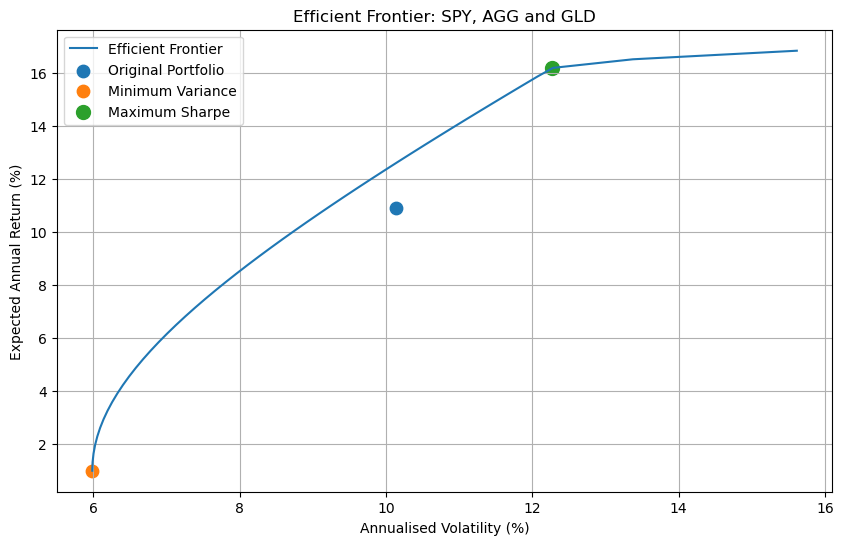

In [26]:

import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Target expected returns
target_returns = np.linspace(
    optimal_weights @ mu,
    mu.max(),
    50
)

frontier_volatility = []
frontier_returns = []

for target in target_returns:

    frontier_constraints = [
        {
            "type": "eq",
            "fun": lambda w: np.sum(w) - 1
        },
        {
            "type": "eq",
            "fun": lambda w, t=target: w @ mu - t
        }
    ]

    frontier_result = minimize(
        portfolio_variance,
        initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=frontier_constraints,
        options={"ftol": 1e-12, "maxiter": 1000}
    )

    if frontier_result.success:
        frontier_volatility.append(
            np.sqrt(frontier_result.fun)
        )
        frontier_returns.append(target)

# Plot efficient frontier
plt.figure(figsize=(10, 6))

plt.plot(
    np.array(frontier_volatility) * 100,
    np.array(frontier_returns) * 100,
    label="Efficient Frontier"
)

plt.scatter(
    portfolio_volatility * 100,
    portfolio_return * 100,
    label="Original Portfolio",
    s=80
)

plt.scatter(
    np.sqrt(result.fun) * 100,
    (optimal_weights @ mu) * 100,
    label="Minimum Variance",
    s=80
)

plt.scatter(
    sharpe_volatility * 100,
    sharpe_return * 100,
    label="Maximum Sharpe",
    s=100
)

plt.xlabel("Annualised Volatility (%)")
plt.ylabel("Expected Annual Return (%)")
plt.title("Efficient Frontier: SPY, AGG and GLD")
plt.legend()
plt.grid(True)
plt.show()


In [27]:
# Minimum variance for the original portfolio's expected return
target = portfolio_return

check_constraints = [
    {"type": "eq", "fun": lambda w: np.sum(w) - 1},
    {"type": "eq", "fun": lambda w: w @ mu - target}
]

check = minimize(
    portfolio_variance,
    initial_weights,
    method="SLSQP",
    bounds=bounds,
    constraints=check_constraints,
    options={"ftol": 1e-12, "maxiter": 1000}
)

if not check.success:
    raise RuntimeError(check.message)

print(f"Original volatility: {portfolio_volatility:.2%}")
print(f"Minimum volatility at same return: {np.sqrt(check.fun):.2%}")

Original volatility: 10.14%
Minimum volatility at same return: 9.20%


In [28]:
print("Efficient allocation at 10.91% expected return:")

for asset, weight in zip(assets, check.x):
    print(f"{asset}: {weight:.2%}")

print(f"\nExpected return: {check.x @ mu:.2%}")
print(f"Volatility: {np.sqrt(check.fun):.2%}")

Efficient allocation at 10.91% expected return:
AGG: 31.96%
GLD: 38.51%
SPY: 29.53%

Expected return: 10.91%
Volatility: 9.20%


In [29]:
import importlib
import src.optimization

importlib.reload(src.optimization)

from src.optimization import minimum_variance

weights_mv = minimum_variance(cov)

print("Minimum-variance portfolio:")

for asset, weight in zip(assets, weights_mv):
    print(f"{asset}: {weight:.2%}")

print(
    f"Volatility: "
    f"{np.sqrt(weights_mv @ cov @ weights_mv):.2%}"
)

Minimum-variance portfolio:
AGG: 92.45%
GLD: 1.94%
SPY: 5.60%
Volatility: 5.98%


In [30]:
import importlib
import src.optimization

importlib.reload(src.optimization)

from src.optimization import (
    maximum_sharpe,
    target_return_min_variance
)

# Maximum Sharpe
w_sharpe = maximum_sharpe(mu, cov, risk_free_rate=0.04)

print("Maximum-Sharpe allocation:")
for asset, weight in zip(assets, w_sharpe):
    print(f"{asset}: {weight:.2%}")

# Minimum variance at the original portfolio's return
w_target = target_return_min_variance(
    mu, cov, portfolio_return
)

print("\nTarget-return efficient allocation:")
for asset, weight in zip(assets, w_target):
    print(f"{asset}: {weight:.2%}")

Maximum-Sharpe allocation:
AGG: 0.00%
GLD: 59.50%
SPY: 40.50%

Target-return efficient allocation:
AGG: 31.96%
GLD: 38.51%
SPY: 29.53%


In [31]:
# Historical training and test periods
train = returns.loc["2021-01-01":"2024-12-31"]
test = returns.loc["2025-01-01":"2025-12-31"]

print("Training observations:", len(train))
print("Test observations:", len(test))

print("Training ends:", train.index.max().date())
print("Testing begins:", test.index.min().date())

Training observations: 1004
Test observations: 250
Training ends: 2024-12-31
Testing begins: 2025-01-02


In [32]:
from src.optimization import minimum_variance, maximum_sharpe

# Estimate model inputs using ONLY training data
mu_train = train.mean().to_numpy() * 252
cov_train = train.cov().to_numpy() * 252

# Fixed benchmark allocation
w_original = np.array([
    {"SPY": 0.50, "AGG": 0.30, "GLD": 0.20}[asset]
    for asset in train.columns
])

# Optimised allocations
w_minvar = minimum_variance(cov_train)

w_maxsharpe = maximum_sharpe(
    mu_train,
    cov_train,
    risk_free_rate=0.04
)

print("\nOriginal:", w_original.round(4))
print("Minimum variance:", w_minvar.round(4))
print("Maximum Sharpe:", w_maxsharpe.round(4))


Original: [0.3 0.2 0.5]
Minimum variance: [0.9201 0.0146 0.0653]
Maximum Sharpe: [0.     0.2664 0.7336]


                  Total Return  Annualised Volatility  Sharpe
Original                0.2321                 0.1088  1.6208
Minimum Variance        0.0867                 0.0453  0.9907
Maximum Sharpe          0.2946                 0.1538  1.5092


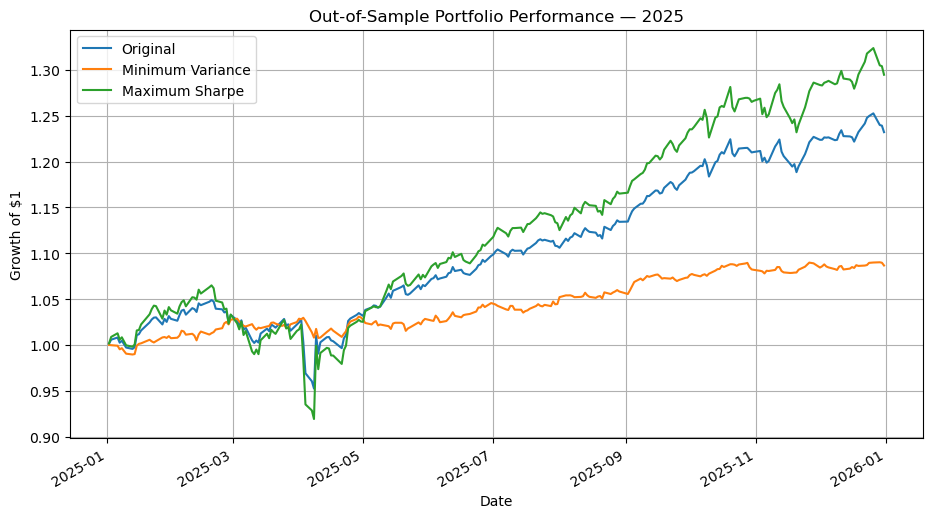

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

strategies = {
    "Original": w_original,
    "Minimum Variance": w_minvar,
    "Maximum Sharpe": w_maxsharpe
}

# Constant-weight daily returns
test_returns = pd.DataFrame({
    name: test.to_numpy() @ weights
    for name, weights in strategies.items()
}, index=test.index)

# Historical test-period growth
test_growth = (1 + test_returns).cumprod()

# Performance metrics
summary = pd.DataFrame({
    "Total Return": (1 + test_returns).prod() - 1,
    "Annualised Volatility": test_returns.std() * np.sqrt(252),
    "Sharpe": (
        test_returns.mean() * 252 - 0.04
    ) / (test_returns.std() * np.sqrt(252))
})

print(summary.round(4))

test_growth.plot(figsize=(11, 6))
plt.title("Out-of-Sample Portfolio Performance — 2025")
plt.ylabel("Growth of $1")
plt.xlabel("Date")
plt.grid(True)
plt.show()

In [34]:
# Out-of-sample maximum drawdown for each strategy

running_peaks = test_growth.cummax()
drawdowns_oos = test_growth / running_peaks - 1

max_drawdowns_oos = drawdowns_oos.min()

print("2025 out-of-sample maximum drawdowns:")
print((max_drawdowns_oos * 100).round(2))

# Compare loss frequencies
loss_frequency = (test_returns < 0).mean()

print("\nPercentage of negative trading days:")
print((loss_frequency * 100).round(2))

2025 out-of-sample maximum drawdowns:
Original            -9.19
Minimum Variance    -2.14
Maximum Sharpe     -13.67
dtype: float64

Percentage of negative trading days:
Original            39.6
Minimum Variance    44.8
Maximum Sharpe      41.2
dtype: float64


In [35]:

# 2025 out-of-sample drawdowns

# Include initial portfolio value of 1
growth = (1 + test_returns).cumprod()
growth = pd.concat([
    pd.DataFrame(
        [np.ones(len(growth.columns))],
        columns=growth.columns,
        index=[test_returns.index[0] - pd.Timedelta(days=1)]
    ),
    growth
])

# Running historical peak
running_peaks = growth.cummax()

# Drawdowns
drawdowns_oos = growth / running_peaks - 1

# Maximum drawdown for each strategy
max_drawdowns_oos = drawdowns_oos.min()

print("2025 Maximum Drawdowns:")
print((max_drawdowns_oos * 100).round(2))

# Frequency of negative-return days
loss_frequency = (test_returns < 0).mean()

print("\nPercentage of Negative Trading Days:")
print((loss_frequency * 100).round(2))


2025 Maximum Drawdowns:
Original            -9.19
Minimum Variance    -2.14
Maximum Sharpe     -13.67
dtype: float64

Percentage of Negative Trading Days:
Original            39.6
Minimum Variance    44.8
Maximum Sharpe      41.2
dtype: float64


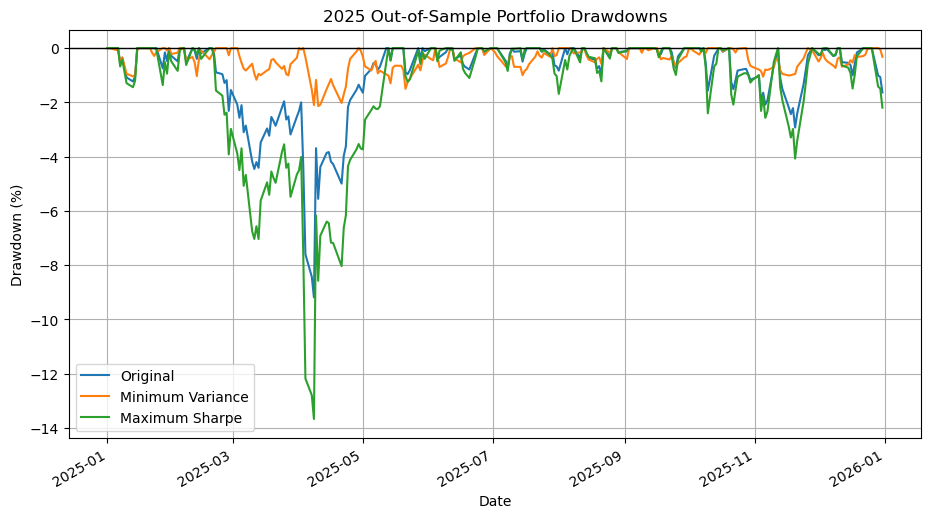

In [36]:
import matplotlib.pyplot as plt

(drawdowns_oos * 100).plot(figsize=(11, 6))

plt.title("2025 Out-of-Sample Portfolio Drawdowns")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.axhline(0, color="black", linewidth=1)
plt.grid(True)
plt.show()

In [37]:
import importlib
import src.backtest

importlib.reload(src.backtest)

from src.backtest import (
    backtest_portfolio,
    backtest_metrics
)

# The fixed original portfolio
w_original_series = pd.Series({
    "SPY": 0.50,
    "AGG": 0.30,
    "GLD": 0.20
})

# Compare different rebalancing rules
for rule in ["daily", "monthly", "none"]:

    result_bt = backtest_portfolio(
        test,
        w_original_series,
        rebalance=rule,
        cost_bps=10
    )

    metrics = backtest_metrics(result_bt)

    print(f"\n{rule.upper()}")
    print(f"Total return: {metrics['total_return']:.2%}")
    print(f"Volatility: {metrics['annual_volatility']:.2%}")
    print(f"Maximum drawdown: {metrics['max_drawdown']:.2%}")
    print(f"Trading costs: ${metrics['total_trading_cost']:,.2f}")


DAILY
Total return: 23.05%
Volatility: 10.88%
Maximum drawdown: -9.21%
Trading costs: $135.77

MONTHLY
Total return: 22.73%
Volatility: 10.72%
Maximum drawdown: -9.08%
Trading costs: $24.54

NONE
Total return: 23.75%
Volatility: 10.63%
Maximum drawdown: -8.75%
Trading costs: $0.00


In [38]:
baseline = backtest_portfolio(
    test,
    w_original_series,
    rebalance="daily",
    cost_bps=0
)

metrics = backtest_metrics(baseline)

print(f"Total return: {metrics['total_return']:.2%}")
print(f"Volatility: {metrics['annual_volatility']:.2%}")
print(f"Sharpe: {metrics['sharpe']:.3f}")
print(f"Drawdown: {metrics['max_drawdown']:.2%}")

Total return: 23.21%
Volatility: 10.88%
Sharpe: 1.621
Drawdown: -9.19%


In [39]:
import importlib
import src.backtest

importlib.reload(src.backtest)

from src.backtest import backtest_portfolio, backtest_metrics

for rule in ["daily", "monthly", "none"]:
    bt = backtest_portfolio(
        test,
        w_original_series,
        rebalance=rule,
        cost_bps=10
    )

    metrics = backtest_metrics(bt)

    print(f"\n{rule.upper()}")
    print("Rebalancing days:", (bt["turnover"] > 0).sum())
    print("Total turnover:", round(bt["turnover"].sum(), 4))
    print("Total return:", f"{metrics['total_return']:.2%}")
    print("Trading costs:", f"${metrics['total_trading_cost']:,.2f}")


DAILY
Rebalancing days: 249
Total turnover: 1.2506
Total return: 23.05%
Trading costs: $135.77

MONTHLY
Rebalancing days: 11
Total turnover: 0.2258
Total return: 22.73%
Trading costs: $24.54

NONE
Rebalancing days: 0
Total turnover: 0.0
Total return: 23.75%
Trading costs: $0.00


In [40]:
import importlib
import src.walk_forward

importlib.reload(src.walk_forward)

from src.walk_forward import walk_forward_backtest

wf_minvar, weights_minvar = walk_forward_backtest(
    returns,
    strategy="minimum_variance",
    training_years=3
)

wf_sharpe, weights_sharpe = walk_forward_backtest(
    returns,
    strategy="maximum_sharpe",
    training_years=3
)

print("Minimum-variance weights:")
print(weights_minvar.round(3))

print("\nMaximum-Sharpe weights:")
print(weights_sharpe.round(3))

print("\nFinal wealth:")
print(f"Minimum variance: ${wf_minvar['wealth'].iloc[-1]:,.2f}")
print(f"Maximum Sharpe: ${wf_sharpe['wealth'].iloc[-1]:,.2f}")

Minimum-variance weights:
        AGG    GLD    SPY
year                     
2024  0.927  0.016  0.057
2025  0.920  0.015  0.065

Maximum-Sharpe weights:
      AGG    GLD    SPY
year                   
2024  0.0  0.000  1.000
2025  0.0  0.266  0.734

Final wealth:
Minimum variance: $111,751.59
Maximum Sharpe: $161,091.29


In [41]:
print("Walk-forward test periods:")
print(wf_minvar.index.min().date())
print(wf_minvar.index.max().date())

print("\nObservations:")
print("Minimum variance:", len(wf_minvar))
print("Maximum Sharpe:", len(wf_sharpe))

print("\nWeights sum to one:")
print(weights_minvar.sum(axis=1))
print(weights_sharpe.sum(axis=1))

Walk-forward test periods:
2024-01-02
2025-12-31

Observations:
Minimum variance: 502
Maximum Sharpe: 502

Weights sum to one:
year
2024    1.0
2025    1.0
dtype: float64
year
2024    1.0
2025    1.0
dtype: float64


In [42]:
import importlib
import src.walk_forward

importlib.reload(src.walk_forward)

from src.walk_forward import walk_forward_backtest

for strategy in ["minimum_variance", "maximum_sharpe"]:

    bt, weights = walk_forward_backtest(
        returns,
        strategy=strategy,
        training_years=3,
        cost_bps=10
    )

    print(f"\n{strategy.upper()}")
    print(f"Final wealth: ${bt['wealth'].iloc[-1]:,.2f}")
    print(f"Total trading costs: ${bt['trading_cost'].sum():,.2f}")

    # Show the turnover and costs on the first
    # trading day of 2025.
    first_2025 = bt.loc["2025"].iloc[0]

    print(f"2025 transition turnover: {first_2025['turnover']:.4f}")
    print(f"2025 transition cost: ${first_2025['trading_cost']:,.2f}")


MINIMUM_VARIANCE
Final wealth: $111,751.59
Total trading costs: $10.20
2025 transition turnover: 0.0169
2025 transition cost: $1.73

MAXIMUM_SHARPE
Final wealth: $161,091.29
Total trading costs: $98.18
2025 transition turnover: 0.5327
2025 transition cost: $66.53


In [43]:
import src.walk_forward
import inspect

print("Module location:")
print(src.walk_forward.__file__)

print("\nFunction source:")
print(inspect.getsource(src.walk_forward.walk_forward_backtest))

Module location:
/Users/admin/portfolio-risk-lab/src/walk_forward.py

Function source:
def walk_forward_backtest(
    returns,
    strategy="minimum_variance",
    training_years=3,
    cost_bps=10,
    risk_free_rate=0.04
):
    """
    Expanding-window, annual walk-forward backtest.

    - Optimise using earlier calendar years.
    - Update target weights annually.
    - Rebalance monthly.
    - Preserve holdings and wealth across years.
    - Charge proportional costs on rebalancing trades.

    Initial acquisition costs are excluded.
    """

    if strategy not in ("minimum_variance", "maximum_sharpe"):
        raise ValueError("Unknown strategy.")

    if not isinstance(training_years, int) or training_years < 1:
        raise ValueError("training_years must be positive.")

    if not isinstance(returns, pd.DataFrame) or returns.empty:
        raise ValueError("Returns must be a nonempty DataFrame.")

    if not isinstance(returns.index, pd.DatetimeIndex):
        raise ValueErro

In [44]:
import importlib
import src.walk_forward

importlib.invalidate_caches()
importlib.reload(src.walk_forward)

from src.walk_forward import walk_forward_backtest

print(src.walk_forward.__file__)

/Users/admin/portfolio-risk-lab/src/walk_forward.py


In [45]:
bt, weights = walk_forward_backtest(
    returns,
    strategy="maximum_sharpe",
    training_years=3,
    cost_bps=10
)

print(weights.round(3))

print(
    bt.loc["2025-01", [
        "turnover",
        "trading_cost"
    ]].head()
)

      AGG    GLD    SPY
year                   
2024  0.0  0.000  1.000
2025  0.0  0.266  0.734
            turnover  trading_cost
date                              
2025-01-02  0.532746      66.53272
2025-01-03  0.000000       0.00000
2025-01-06  0.000000       0.00000
2025-01-07  0.000000       0.00000
2025-01-08  0.000000       0.00000


In [47]:
import importlib
import src.walk_forward

importlib.reload(src.walk_forward)

from src.walk_forward import walk_forward_backtest

In [48]:
bt, weights = walk_forward_backtest(
    returns,
    strategy="maximum_sharpe",
    training_years=3,
    cost_bps=10
)

print("Annual weights:")
print(weights.round(3))

print("\nFirst five trading days of January 2025:")
print(
    bt.loc["2025-01", [
        "turnover",
        "trading_cost"
    ]].head()
)

Annual weights:
      AGG    GLD    SPY
year                   
2024  0.0  0.000  1.000
2025  0.0  0.266  0.734

First five trading days of January 2025:
            turnover  trading_cost
date                              
2025-01-02  0.532746      66.53272
2025-01-03  0.000000       0.00000
2025-01-06  0.000000       0.00000
2025-01-07  0.000000       0.00000
2025-01-08  0.000000       0.00000
